# Multimodal Analysis

## Purpose

This notebook configures and explores the performance in each modality (visual, auditory, audiovisual) across sessions.

## Available Functions

- **Modality performance:** Visualize the performance in each modality across sessions using `get_linePlot_per_modality_across_sessions`, `get_scatter_plot_modalities`.

<div class="alert alert-info">
<strong>Note:</strong> Session IDs are stored in <code>config/beh_sessions.json</code>, organized by <code>animal_id</code> and <code>task_type</code> (e.g., <i>visual</i> , <i>audiovisual</i>).
</div>

In [1]:
from multimodal_analysis.db import get_schema_modules, get_schemas

exp, stim, beh, inter, rec, mice = get_schema_modules()

from multimodal_analysis.config import create_analysis_key, get_behavior_sessions
from multimodal_analysis.plots import (
    get_linePlot_per_modality_across_sessions,
    get_scatter_plot_modalities,
)

Please enter DataJoint username:  eflab
Please enter DataJoint password:  ········


[2026-10-16 14:46:11,924][INFO]: Connecting eflab@database.eflab.org:3306
[2026-10-16 14:46:11,955][INFO]: Connected eflab@database.eflab.org:3306


In [2]:
# Define the animal and behavioral task for the analysis
# Set animal_id to None to include all animals
# Available task types: "visual", "audiovisual", "audiovisual_diff", "audiovisual_no_stim",
# "audiovisual_obj215", "audiovisual_conflicted"
animal_id = 410
task_type = "audiovisual"

# Define the difficulty levels and sessions to exclude.
difficulties = [2]
excluded_sessions = []

In [7]:
# Get the behavioral sessions available for the selected animal and task.
sessions_idx = get_behavior_sessions(animal_id=animal_id, task_type=task_type)
print("sessions_idx: \n", sessions_idx)

# Define the first session to include in the analysis.
from_session = get_behavior_sessions(animal_id=animal_id, task_type=task_type)[10]
print("\nfrom_session:", from_session)

# Define the last session to include in the analysis.
to_session = get_behavior_sessions(animal_id=animal_id, task_type=task_type)[-1]
print("to_session:", to_session)

# Calculate the total number of sessions included in the analysis.
total_sessions = len(sessions_idx[:])
print("total_sessions:", total_sessions)

sessions_idx: 
 [135, 136, 137, 138, 139, 141, 144, 145, 146, 147, 148, 149, 151, 152, 154, 155, 156, 157, 158, 160, 161, 165, 167, 171, 173, 176, 178, 180, 181, 182, 184, 186, 189, 191, 194, 196]

from_session: 148
to_session: 196
total_sessions: 36


In [8]:
# Create the analysis configuration for the selected animal and sessions.
# Parameters:
# animal_id (int): Animal ID.
# from_session (int): First session.
# to_session (int): Last session.
# difficulties (list): Difficulty levels to include.
# excluded_sessions (list): Sessions to exclude.
key = create_analysis_key(
    animal_id, from_session, to_session, difficulties, excluded_sessions
)
print(key)

{'animal_id': 410, 'sessions': (148, 196), 'difficulties': [2], 'excluded_sessions': []}


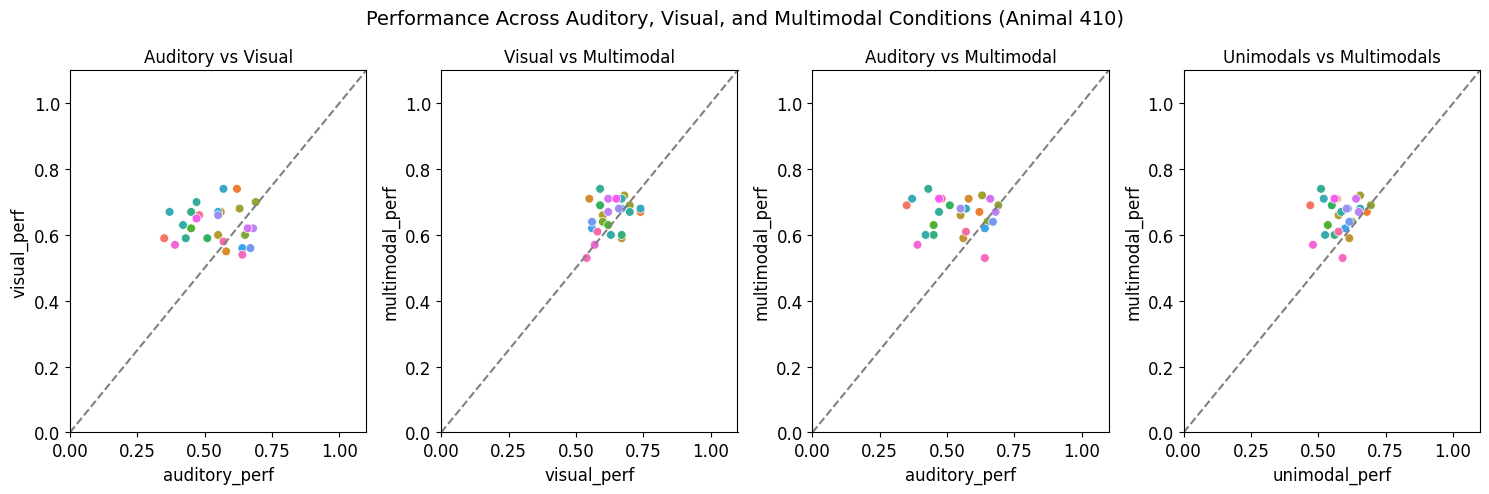

In [9]:
# Plot performance comparisons across sensory modalities
# Parameters:
# key (dict), stim (stimulus schema), exp (experiment schema)
get_scatter_plot_modalities(key, stim, exp)

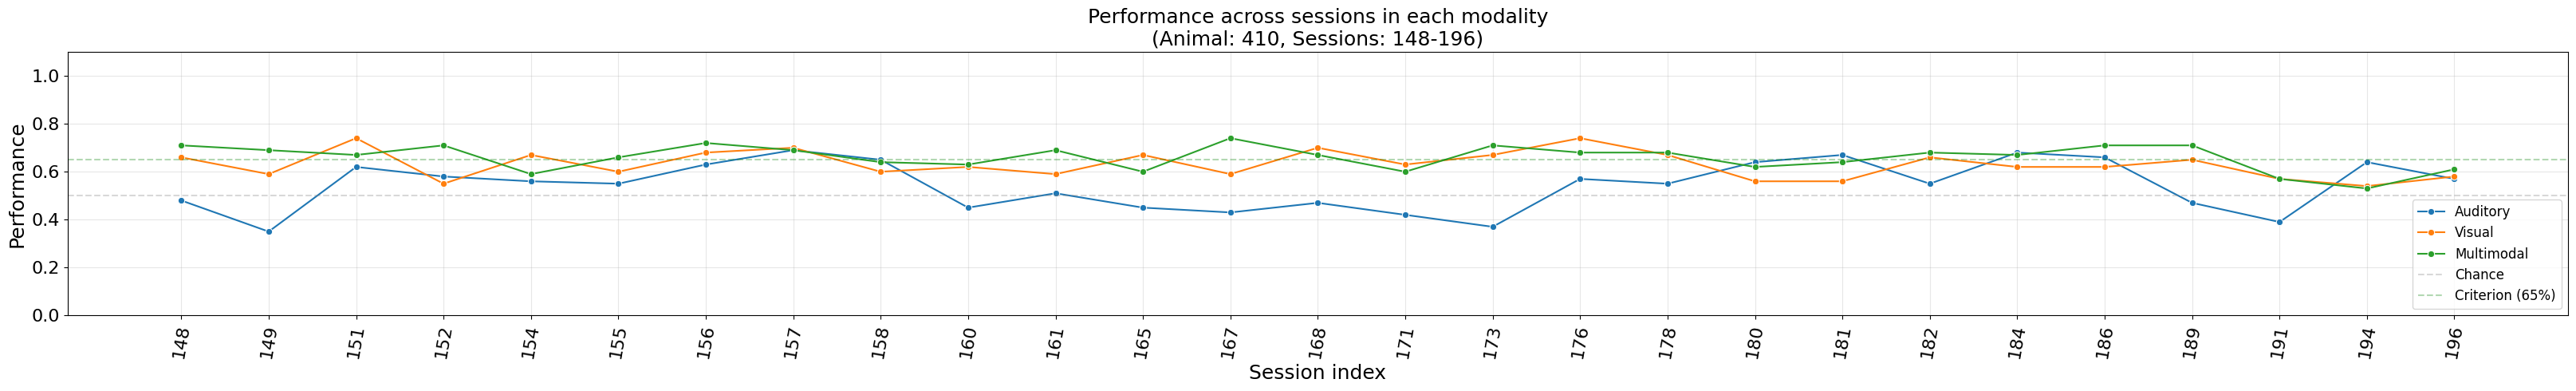

In [10]:
# Plot performance across sessions for each modality
# Parameters:
# key (dict), stim (stimulus schema), exp (experiment schema), criterion (float)
get_linePlot_per_modality_across_sessions(key, stim, exp, criterion=0.65)